In [1]:
from sklearn.svm import SVC, LinearSVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [3]:
from sklearn import set_config
set_config(display="text")

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

svcMD = SVC(kernel='linear')
svcMD.fit(X_train, y_train)

SVC(kernel='linear')

In [4]:
print("SVC 학습 데이터 점수 : {:.3f}".format(svcMD.score(X_train, y_train)))
print("SVC 테스트 데이터 점수 : {:.3f}".format(svcMD.score(X_test, y_test)))

SVC 학습 데이터 점수 : 0.975
SVC 테스트 데이터 점수 : 1.000


In [5]:
scaler = StandardScaler()
# scaler = MinMaxScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# scaledSVC = SVC(kernel='linear')
# scaledSVC = SVC(kernel='rbf', C=10, gamma=0.1)
# scaledSVC = SVC(kernel='rbf', C=1, gamma=5)
scaledSVC = SVC(kernel='poly', degree=10, coef0=1, C=1)
scaledSVC.fit(X_train, y_train)
print("표준화 후 SVC 학습 데이터 점수 : {:.3f}".format(scaledSVC.score(X_train, y_train)))
print("표준화 후 SVC 테스트 데이터 점수 : {:.3f}".format(scaledSVC.score(X_test, y_test)))

표준화 후 SVC 학습 데이터 점수 : 1.000
표준화 후 SVC 테스트 데이터 점수 : 0.967


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) # FutureWarning 제거

In [8]:
def make_mg(x, y, h=0.05) :         # 특징값 x, y에 대한 meshgrid 만들기
    x_min, x_max = x.min()-1, x.max()+1
    y_min, y_max = y.min()-1, y.max()+1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                       np.arange(y_min, y_max, h))
    return xx, yy

def plot_cnts(md, xx, yy, **params) :  # meshgrid xx, yy를 이용해 분류값별로 영역 표시하기
    Z = md.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = plt.contourf(xx, yy, Z, **params)
    return out

In [9]:
Xc = TSNE(n_components=2, random_state=2).fit_transform(X);
X0, X1 = Xc[:, 0], Xc[:, 1]
xx, yy = make_mg(X0, X1)
# plt.scatter(X0, X1);

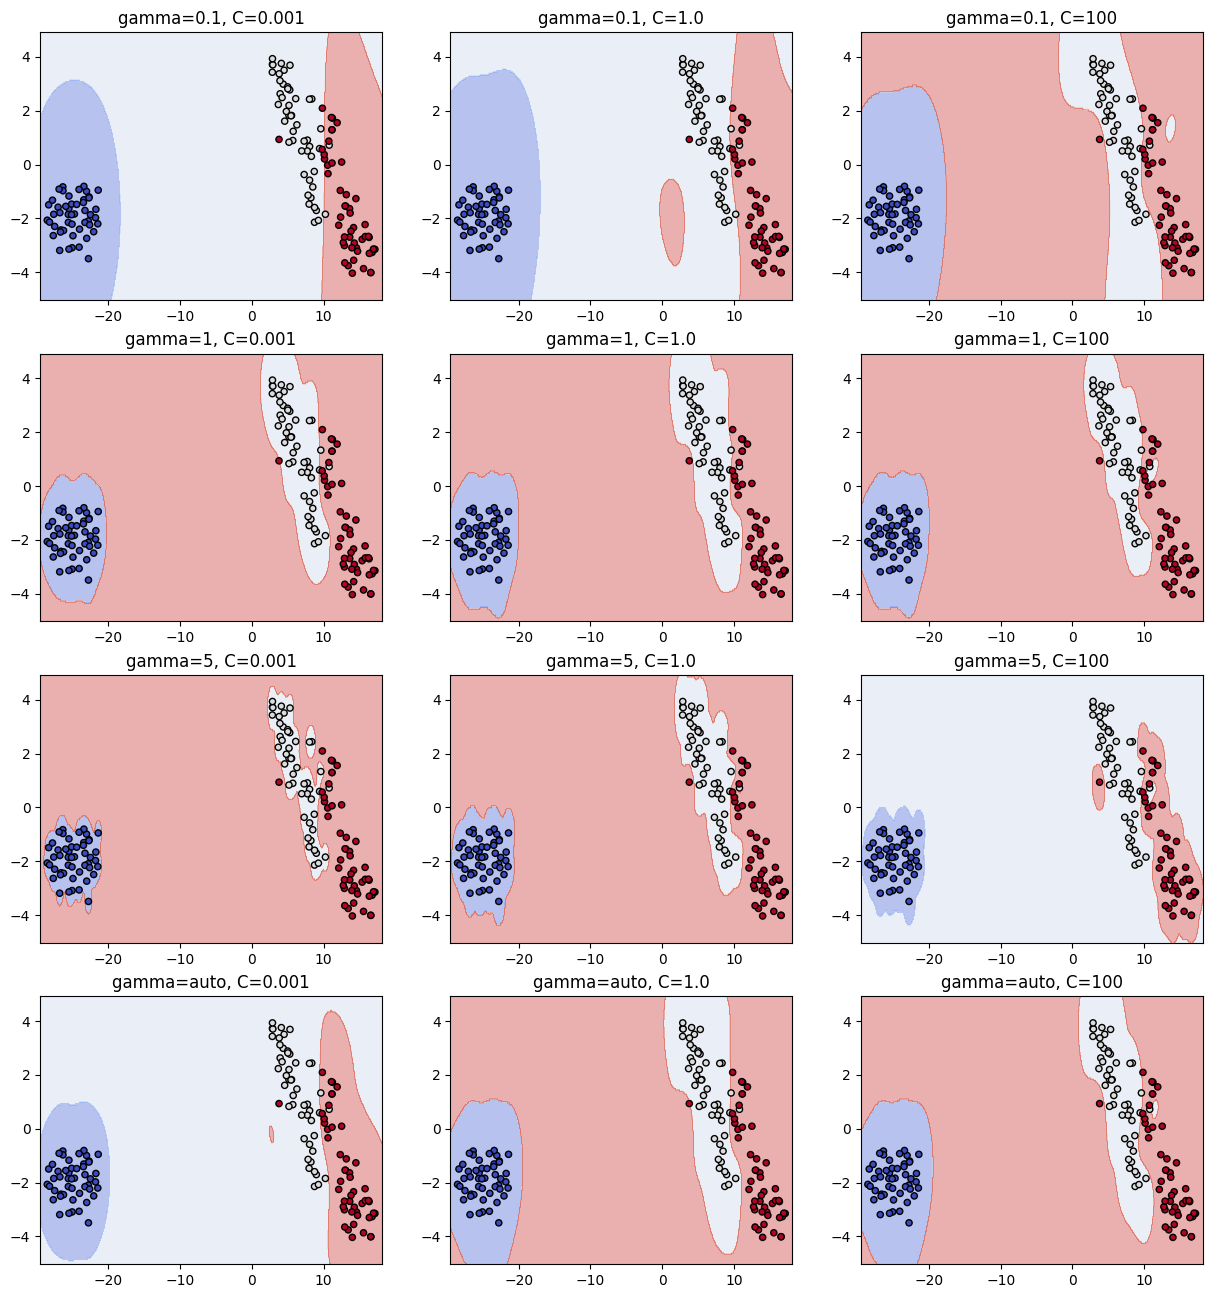

In [10]:
gamma=[0.1, 1, 5, 'auto']
C=[0.001, 1.0, 100]
row = len(gamma)
col = len(C)

plt.figure(figsize=(5*col,4*row))  # width x height
i = 1
for g in gamma:
    for c in C:
        plt.subplot(row,col,i)
        testSVC = SVC(kernel='rbf', C=c, gamma=g)
        testSVC.fit(Xc, y)
        plot_cnts(testSVC, xx, yy, cmap=plt.cm.coolwarm, alpha=0.4)
        plt.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors='k')
        plt.title("gamma={}, C={}".format(g, c))
        i += 1


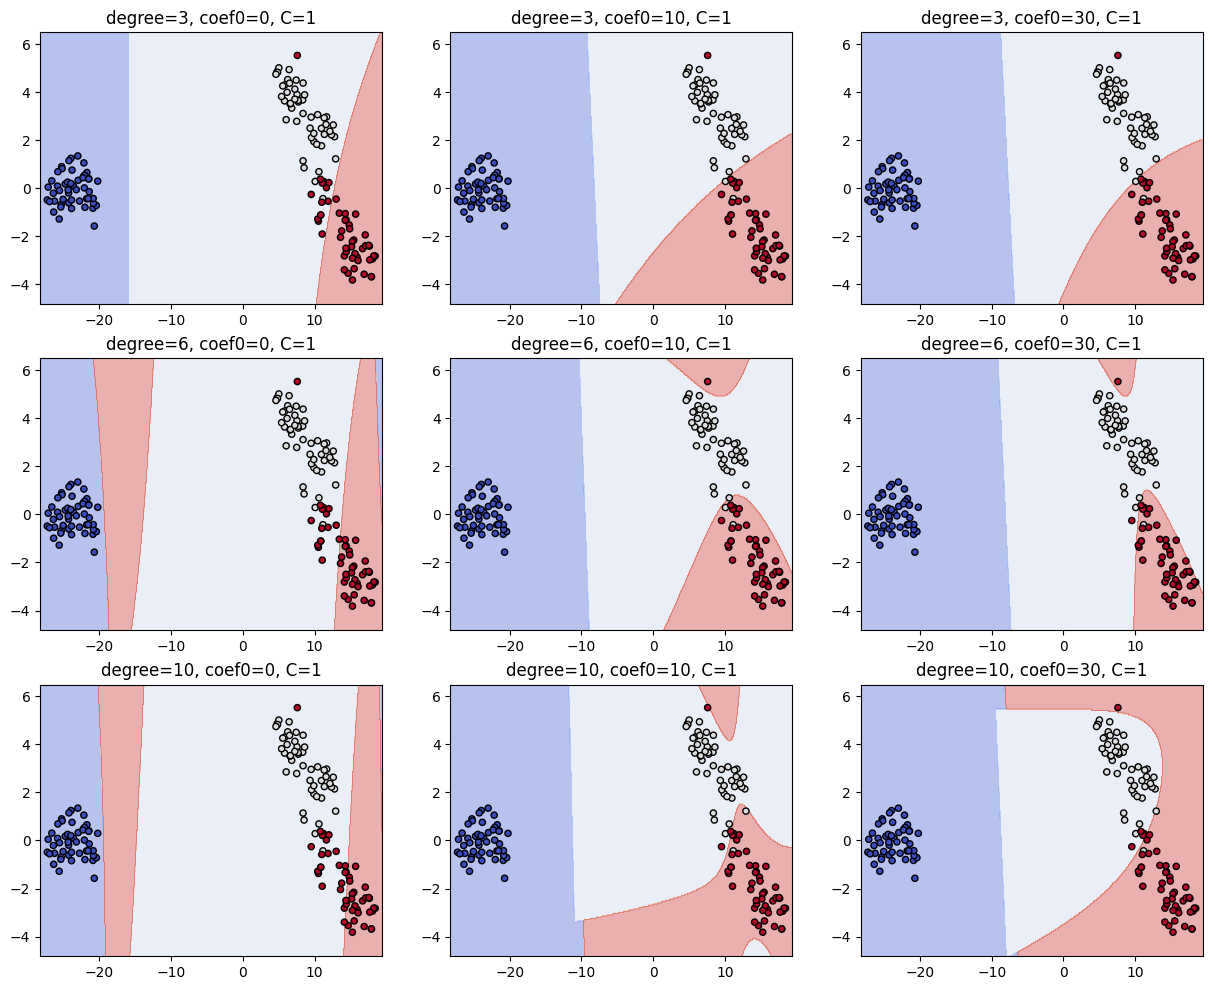

In [ ]:
degree=[3, 6, 10]  # 차수를 높일수록 계산량이 과도하게 증가함
coef0=[0,10,30]
reg = 1
row = len(degree)
col = len(coef0)

plt.figure(figsize=(5*col,4*row))  # width x height
i = 1
for d in degree:
    for c in coef0:
        plt.subplot(row,col,i)
        testSVC = SVC(kernel='poly', degree=d, coef0=c, C=reg)
        testSVC.fit(Xc, y)
        plot_cnts(testSVC, xx, yy, cmap=plt.cm.coolwarm, alpha=0.4)
        plt.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors='k')
        plt.title("degree={}, coef0={}, C={}".format(d, c, reg))
        i += 1